# Case 2: the Gandak River flood seen by NISAR radar (Bihar, India, September 2026)

NISAR is the new NASA and ISRO radar satellite. A radar sends its own microwave pulses and records the echo, so it sees the ground **through clouds and at night**. That matters here: the monsoon clouds hid the September 2026 Gandak flood from optical satellites, but NISAR imaged it on the day of the peak.

This notebook, read from top to bottom:

1. **Study area**: where we look, on a satellite photo.

Only one radar channel is used (**HH**) and every rule is a simple comparison of two numbers per pixel.

In [ ]:
import json
import time
import urllib.request
from pathlib import Path

import earthaccess
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401  (adds the .rio tools to xarray)
import xarray as xr
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from pyproj import Transformer
from scipy import ndimage

DATA = Path("../data/case2")      # this notebook lives in dataScience/notebooks/
CACHE = DATA / "cache"            # downloads (large, not committed to git)
EXPORT = DATA / "export"          # the package for the app (small, committed)
CACHE.mkdir(parents=True, exist_ok=True)
EXPORT.mkdir(parents=True, exist_ok=True)

BBOX = (84.15, 26.10, 84.75, 26.60)   # study box: west, south, east, north (degrees)
UTM = 32644                           # UTM zone 44N: the map grid of the NISAR files here
PIXEL_M = 20                          # analysis pixel size (metres)
BEFORE, PEAK, AFTER = "2026-09-04", "2026-09-28", "2026-10-10"

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "font.size": 9})

### Map helpers

All maps share one grid: 20 m pixels in UTM zone 44N covering the study box. Every radar date and the satellite photo are resampled onto it, so pixel `[row, col]` is the same spot on the ground in every image.

In [ ]:
def make_grid(bbox, epsg, res):
    """Empty 20 m grid (UTM) that covers the lon/lat box."""
    tr = Transformer.from_crs(4326, epsg, always_xy=True)
    xs, ys = tr.transform([bbox[0], bbox[2], bbox[0], bbox[2]], [bbox[1], bbox[1], bbox[3], bbox[3]])
    x0, x1 = np.floor(min(xs) / res) * res, np.ceil(max(xs) / res) * res
    y0, y1 = np.floor(min(ys) / res) * res, np.ceil(max(ys) / res) * res
    x = np.arange(x0 + res / 2, x1, res)
    y = np.arange(y1 - res / 2, y0, -res)
    return xr.DataArray(np.zeros((y.size, x.size), "float32"), coords={"y": y, "x": x}, dims=("y", "x")).rio.write_crs(epsg)


GRID = make_grid(BBOX, UTM, PIXEL_M)
EXTENT = [float(GRID.x[0]) - 10, float(GRID.x[-1]) + 10, float(GRID.y[-1]) - 10, float(GRID.y[0]) + 10]
to_utm = Transformer.from_crs(4326, UTM, always_xy=True).transform


def box_utm(w, s, e, n):
    """Outline of a lon/lat box in grid coordinates (for drawing)."""
    lon = [w, e, e, w, w]
    lat = [s, s, n, n, s]
    return to_utm(lon, lat)


def zoom_to(ax, w, s, e, n):
    xs, ys = box_utm(w, s, e, n)
    ax.set_xlim(min(xs), max(xs))
    ax.set_ylim(min(ys), max(ys))


def scale_bar(ax, km=10):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x, y = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color="white", lw=3)
    ax.text(x + km * 500, y + 0.015 * (y1 - y0), f"{km} km", color="white", ha="center", fontsize=8)


def radar_axes(ax, title):
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


def show_radar(ax, db, title, vmin=-25, vmax=0):
    """Grey radar image in dB: dark = little echo (smooth water), bright = strong echo."""
    im = ax.imshow(db, cmap="gray", vmin=vmin, vmax=vmax, extent=EXTENT, interpolation="nearest")
    radar_axes(ax, title)
    return im


def show_classes(ax, codes, colors):
    """Colour the pixels whose code is in `colors` ({code: hex}); others stay transparent."""
    rgba = np.zeros(codes.shape + (4,), "uint8")   # 8-bit colours keep the memory low
    for k, hexcol in colors.items():
        rgba[codes == k] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    ax.imshow(rgba, extent=EXTENT, interpolation="nearest")


print(f"Grid: {GRID.sizes['y']} x {GRID.sizes['x']} pixels of {PIXEL_M} m, EPSG:{UTM}")

Grid: 2853 x 3071 pixels of 20 m, EPSG:32644


## 1. The study area, seen from space

The **Gandak River** comes down from the Himalaya in Nepal and crosses the plain of Bihar (India) towards the Ganges. Our box is about **60 km by 55 km** around **Gopalganj**, on the Gandak floodplain.

What happened: heavy rain in Nepal on **September 26 and 27, 2026** pushed the Gandak to a record **91.25 m at Bagaha**. The Valmikinagar barrage released **543,500 cusecs** on the morning of **September 28**, and embankments breached in West Champaran and at **Sheetalpur (Gopalganj)**. NISAR passed over the box that same evening.

The photo below is a normal colour image from the European **Sentinel-2** satellite on **June 25, 2026**, before the monsoon flood and with no cloud. It shows the river, the fields and the towns we refer to later. It is fetched from the free **Earth Search** catalogue (no login).

In [ ]:
STAC = "https://earth-search.aws.element84.com/v1/search"


def stac_search(collection, bbox, day):
    """Images of one collection that touch the box on one day (public STAC API)."""
    body = {"collections": [collection], "bbox": list(bbox), "limit": 20,
            "datetime": f"{day}T00:00:00Z/{day}T23:59:59Z"}
    req = urllib.request.Request(STAC, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
    return json.load(urllib.request.urlopen(req, timeout=120))["features"]


def sentinel2_photo(day):
    """True-colour Sentinel-2 photo on our grid; tiles are read over the internet, only the box is kept."""
    path = CACHE / f"sentinel2_{day}.tif"
    if path.exists():
        return rioxarray.open_rasterio(path)
    items = sorted(stac_search("sentinel-2-l2a", BBOX, day), key=lambda f: f["properties"]["eo:cloud_cover"])
    rgb = None
    for item in items:
        tile = rioxarray.open_rasterio(item["assets"]["visual"]["href"], overview_level=0)  # 20 m version
        try:
            tile = tile.rio.clip_box(*BBOX, crs="EPSG:4326")
        except Exception:
            continue  # this tile does not touch the box
        part = tile.rio.reproject_match(GRID, nodata=0)
        rgb = part if rgb is None else rgb.where((rgb != 0).any("band"), part)
        print(f"  {item['id']}: {item['properties']['eo:cloud_cover']:.1f} % cloud")
    rgb = rgb.astype("uint8").rio.write_crs(UTM)
    rgb.rio.to_raster(path, compress="deflate")
    return rgb


PHOTO_DAY = "2026-06-25"
photo = sentinel2_photo(PHOTO_DAY)
photo_rgb = np.moveaxis(photo.values, 0, -1)

In [ ]:
import osmnx as ox

OVERPASS = ("https://overpass-api.de/api", "https://overpass.kumi.systems/api")
ox.settings.cache_folder = str(CACHE / "osmnx")   # osmnx's own download cache, kept with ours (not committed)


def osm(tags, name):
    """OpenStreetMap features in the box (Overpass API), cached as GeoJSON."""
    path = CACHE / f"osm_{name}.geojson"
    if path.exists():
        return gpd.read_file(path)
    for attempt in range(3):
        for url in OVERPASS:
            try:
                ox.settings.overpass_url = url
                gdf = ox.features_from_bbox(BBOX, tags).reset_index()
                cols = [c for c in ("name", "place", "waterway") if c in gdf.columns]
                gdf = gdf[cols + ["geometry"]]
                gdf.to_file(path, driver="GeoJSON")
                return gdf
            except Exception as exc:
                print(f"  Overpass {url} failed ({type(exc).__name__}), trying again")
        time.sleep(20 * (attempt + 1))
    raise RuntimeError("OpenStreetMap is not reachable right now; run this cell again later")


towns = osm({"place": ["city", "town"]}, "towns")
towns = towns[(towns.geometry.geom_type == "Point") & towns["name"].notna()].reset_index(drop=True)
rivers = osm({"waterway": "river"}, "rivers")
gandak = rivers[(rivers["name"] == "Gandak") & rivers.geometry.geom_type.isin(["LineString", "MultiLineString"])]
print("Towns:", ", ".join(towns["name"]))
print("Gandak river segments:", len(gandak))

# World map for the small locator inset (Natural Earth, public domain)
world_path = CACHE / "natural_earth_countries.geojson"
if not world_path.exists():
    gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip").to_file(world_path, driver="GeoJSON")
world = gpd.read_file(world_path)

Towns: Siwan, Mirganj, Mairwa, Gopalganj, Barharia, Maharajganj
Gandak river segments: 8


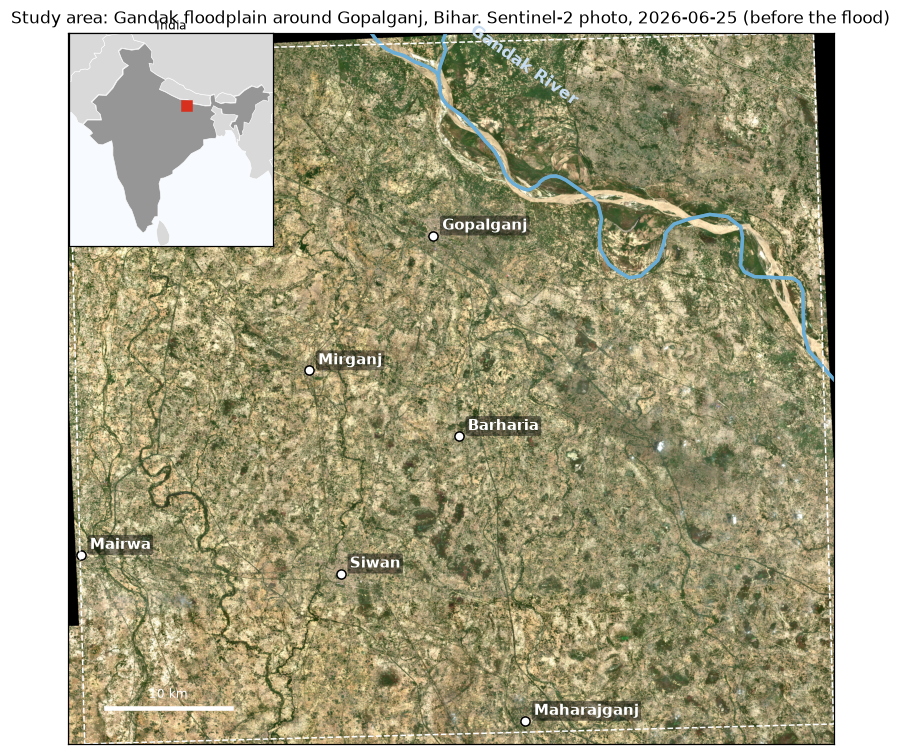

In [ ]:
fig, ax = plt.subplots(figsize=(9, 8.4))
ax.imshow(photo_rgb, extent=EXTENT)
for geom in gandak.to_crs(UTM).geometry:
    for line in getattr(geom, "geoms", [geom]):
        ax.plot(*line.xy, color="#6baed6", lw=2.2, alpha=0.9)
for _, t in towns.to_crs(UTM).iterrows():
    ax.plot(t.geometry.x, t.geometry.y, "o", ms=6, mfc="white", mec="black")
    ax.annotate(t["name"], (t.geometry.x, t.geometry.y), xytext=(6, 4), textcoords="offset points",
                color="white", fontsize=10, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.45, lw=0))
gx, gy = to_utm(84.47, 26.555)
ax.annotate("Gandak River", (gx, gy), color="#c6dbef", fontsize=11, fontweight="bold", rotation=-35)
ax.plot(*box_utm(*BBOX), color="white", lw=1, ls="--")
ax.set_xlim(EXTENT[:2])
ax.set_ylim(EXTENT[2:])
radar_axes(ax, f"Study area: Gandak floodplain around Gopalganj, Bihar. Sentinel-2 photo, {PHOTO_DAY} (before the flood)")
scale_bar(ax)

inset = ax.inset_axes([0.0, 0.70, 0.27, 0.30])
world.plot(ax=inset, color="#d9d9d9", edgecolor="white", lw=0.4)
world[world["NAME"] == "India"].plot(ax=inset, color="#969696", edgecolor="white", lw=0.4)
inset.plot(np.mean(BBOX[::2]), np.mean(BBOX[1::2]), "s", color="#d7301f", ms=6)
inset.set_xlim(66, 98)
inset.set_ylim(6, 37)
inset.set_xticks([])
inset.set_yticks([])
inset.set_xlabel("")
inset.set_ylabel("")
inset.set_facecolor("#f7fbff")
inset.set_title("India", fontsize=8, pad=2)
plt.show()